In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

print(os.listdir('/content/drive/MyDrive/'))

['rophi.jpg', 'ĐỀ THI THỬ NGÀY 24-3.gdoc', '001_ESTE__LIPIT.pdf', 'HÓA ĐỊNH KÌ (29.4.2020).gdoc', 'Classroom', 'TASK 1 - WRAP UP.gdoc', 'DSCF5376 (2) (1).JPG', 'DSCF5376 (2).JPG', 'thelotus-1.docx', 'Lotus', 'Bài luận - Sáng tạo - Hài hước.gdoc', 'Tài liệu không có tiêu đề (29).gdoc', 'Caption The Lotus.gdoc', 'Hình thành viên', 'Vinh.jpg', 'Bảng tính không có tiêu đề (1).gsheet', 'ContentPC.docx', 'Tài liệu không có tiêu đề (28).gdoc', '3. Pre 2020 Tong hop thong tin du an cong dong _[SK...]_Review of Community Project.gsheet', '3. Pre 2020 Tong hop thong tin du an cong dong _[SK...]_Review of Community Project.xlsx', 'Trả lời sự kiện.gform', 'Trả lời sự kiện (Câu trả lời).gsheet', 'Bảng tính chưa có tiêu đề (1).gsheet', 'Mẫu không có tiêu đề.gform', 'cbo-hnrd-dok – 27 thg 7, 2021.pdf', 'xanhla+hong.jpg', 'Tài liệu không có tiêu đề (27).gdoc', 'prp-breh-rjd – 9 thg 1, 2022.pdf', 'FA.2 - Cover.png', 'VRC

In [3]:
yaml_content = """
path: /content/drive/MyDrive/Dataset

train: images/train
val: images/val
test: images/test

names:
  0: pest
"""

with open("/content/dataset.yaml", "w") as f:
    f.write(yaml_content)

In [4]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 10.4 MB/s eta 0:00:00


In [5]:

from ultralytics import YOLO

model = YOLO("yolov8s.pt")

model.train(
    data="/content/dataset.yaml",
    epochs=100,
    imgsz=960,
    batch=16
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c153c1bfd20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

Biểu đồ tổng hợp Train Loss và mAP:


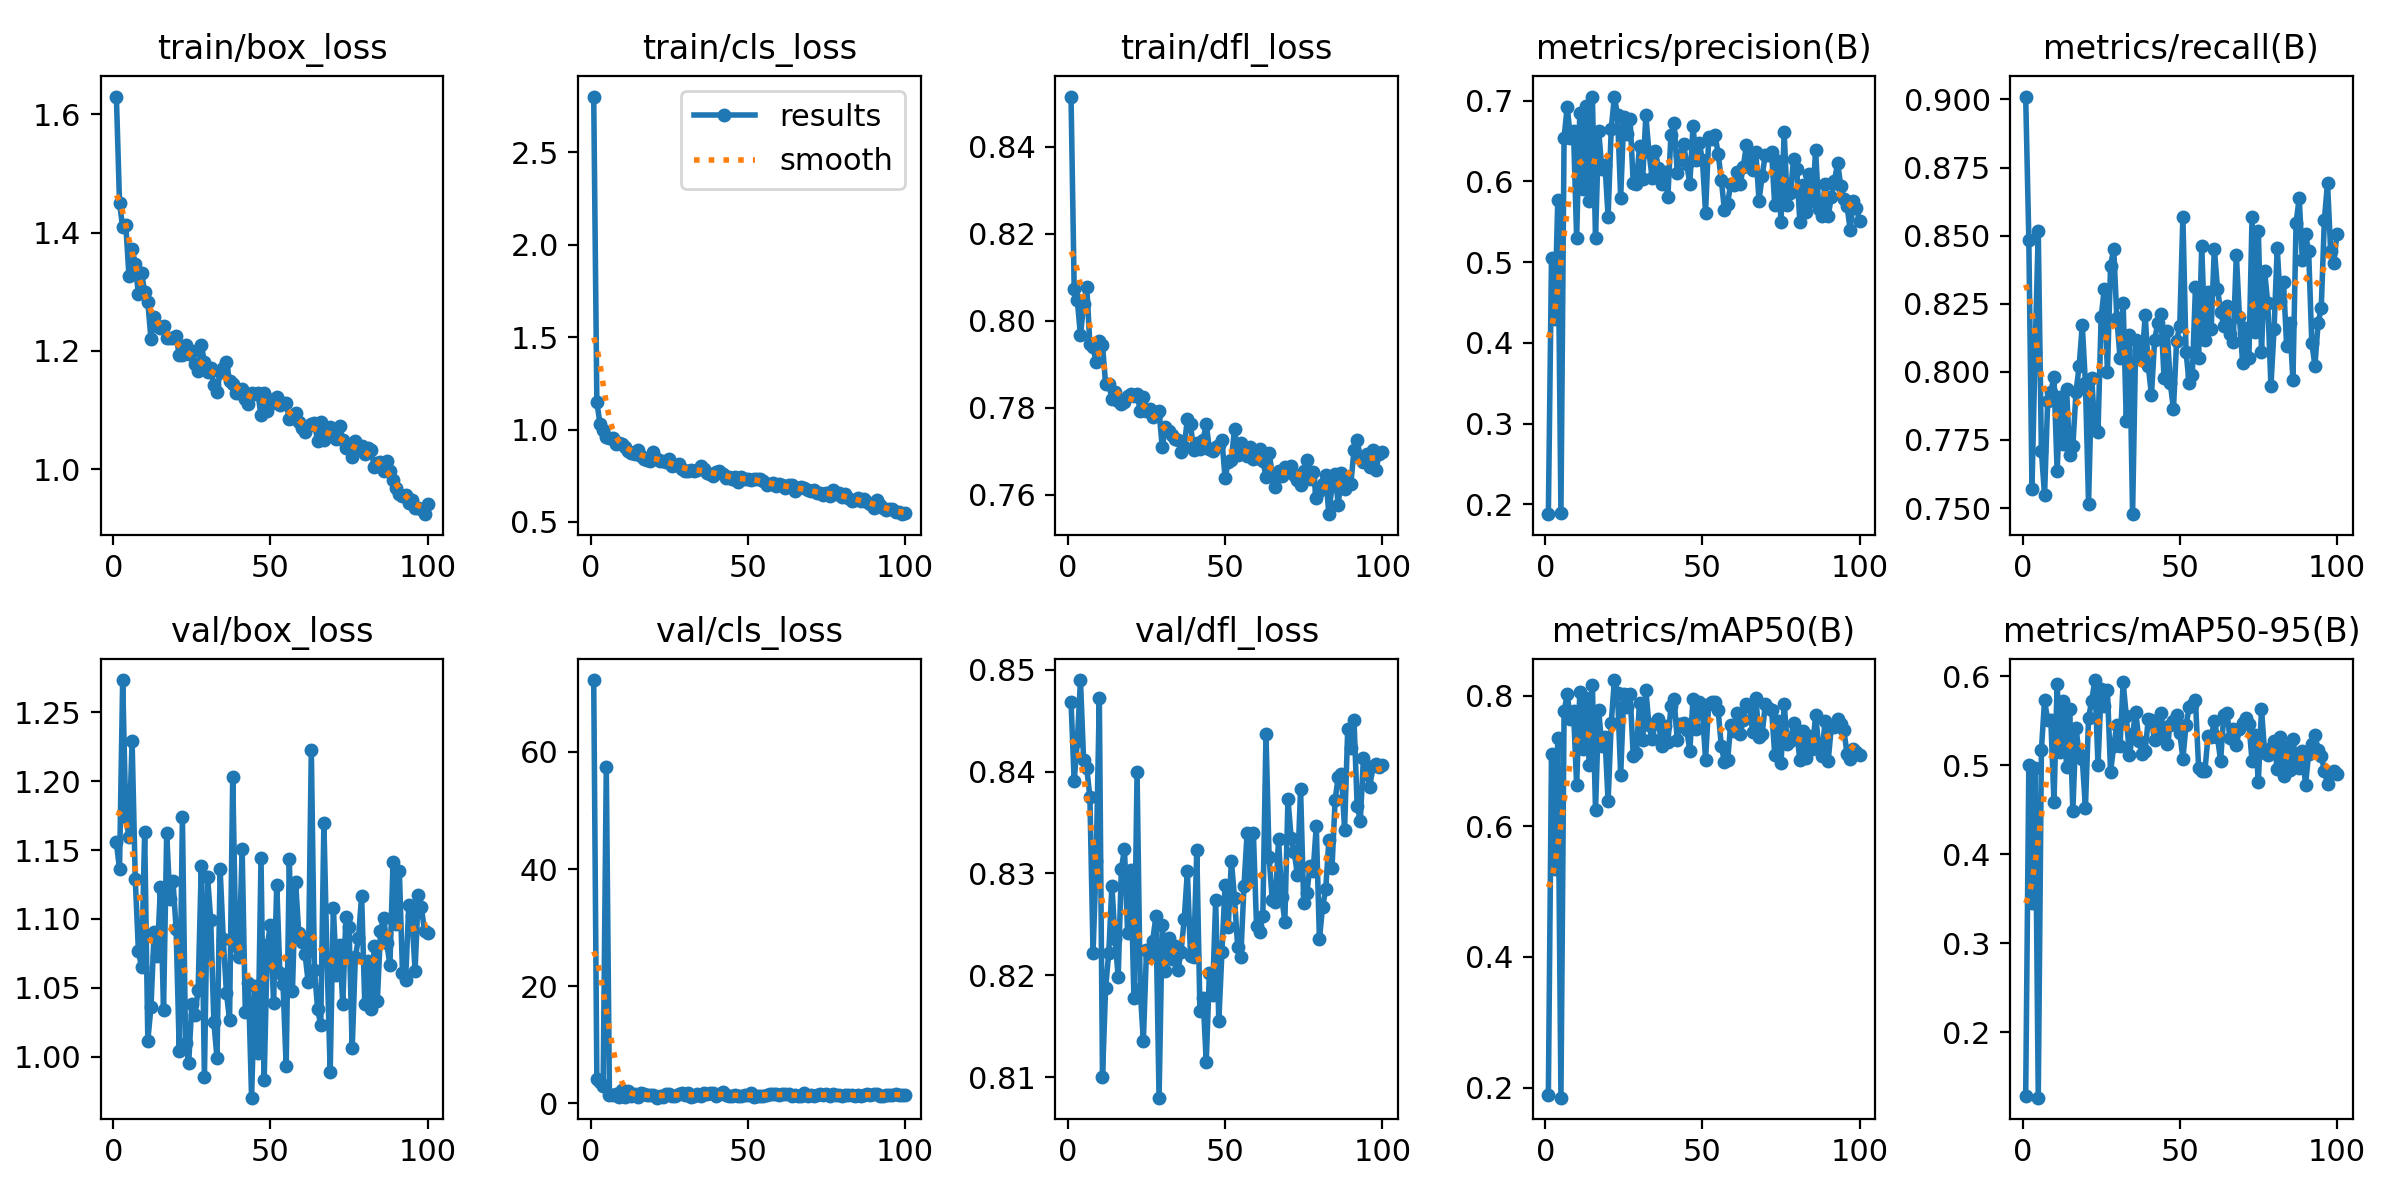


Ma trận nhầm lẫn (Confusion Matrix):


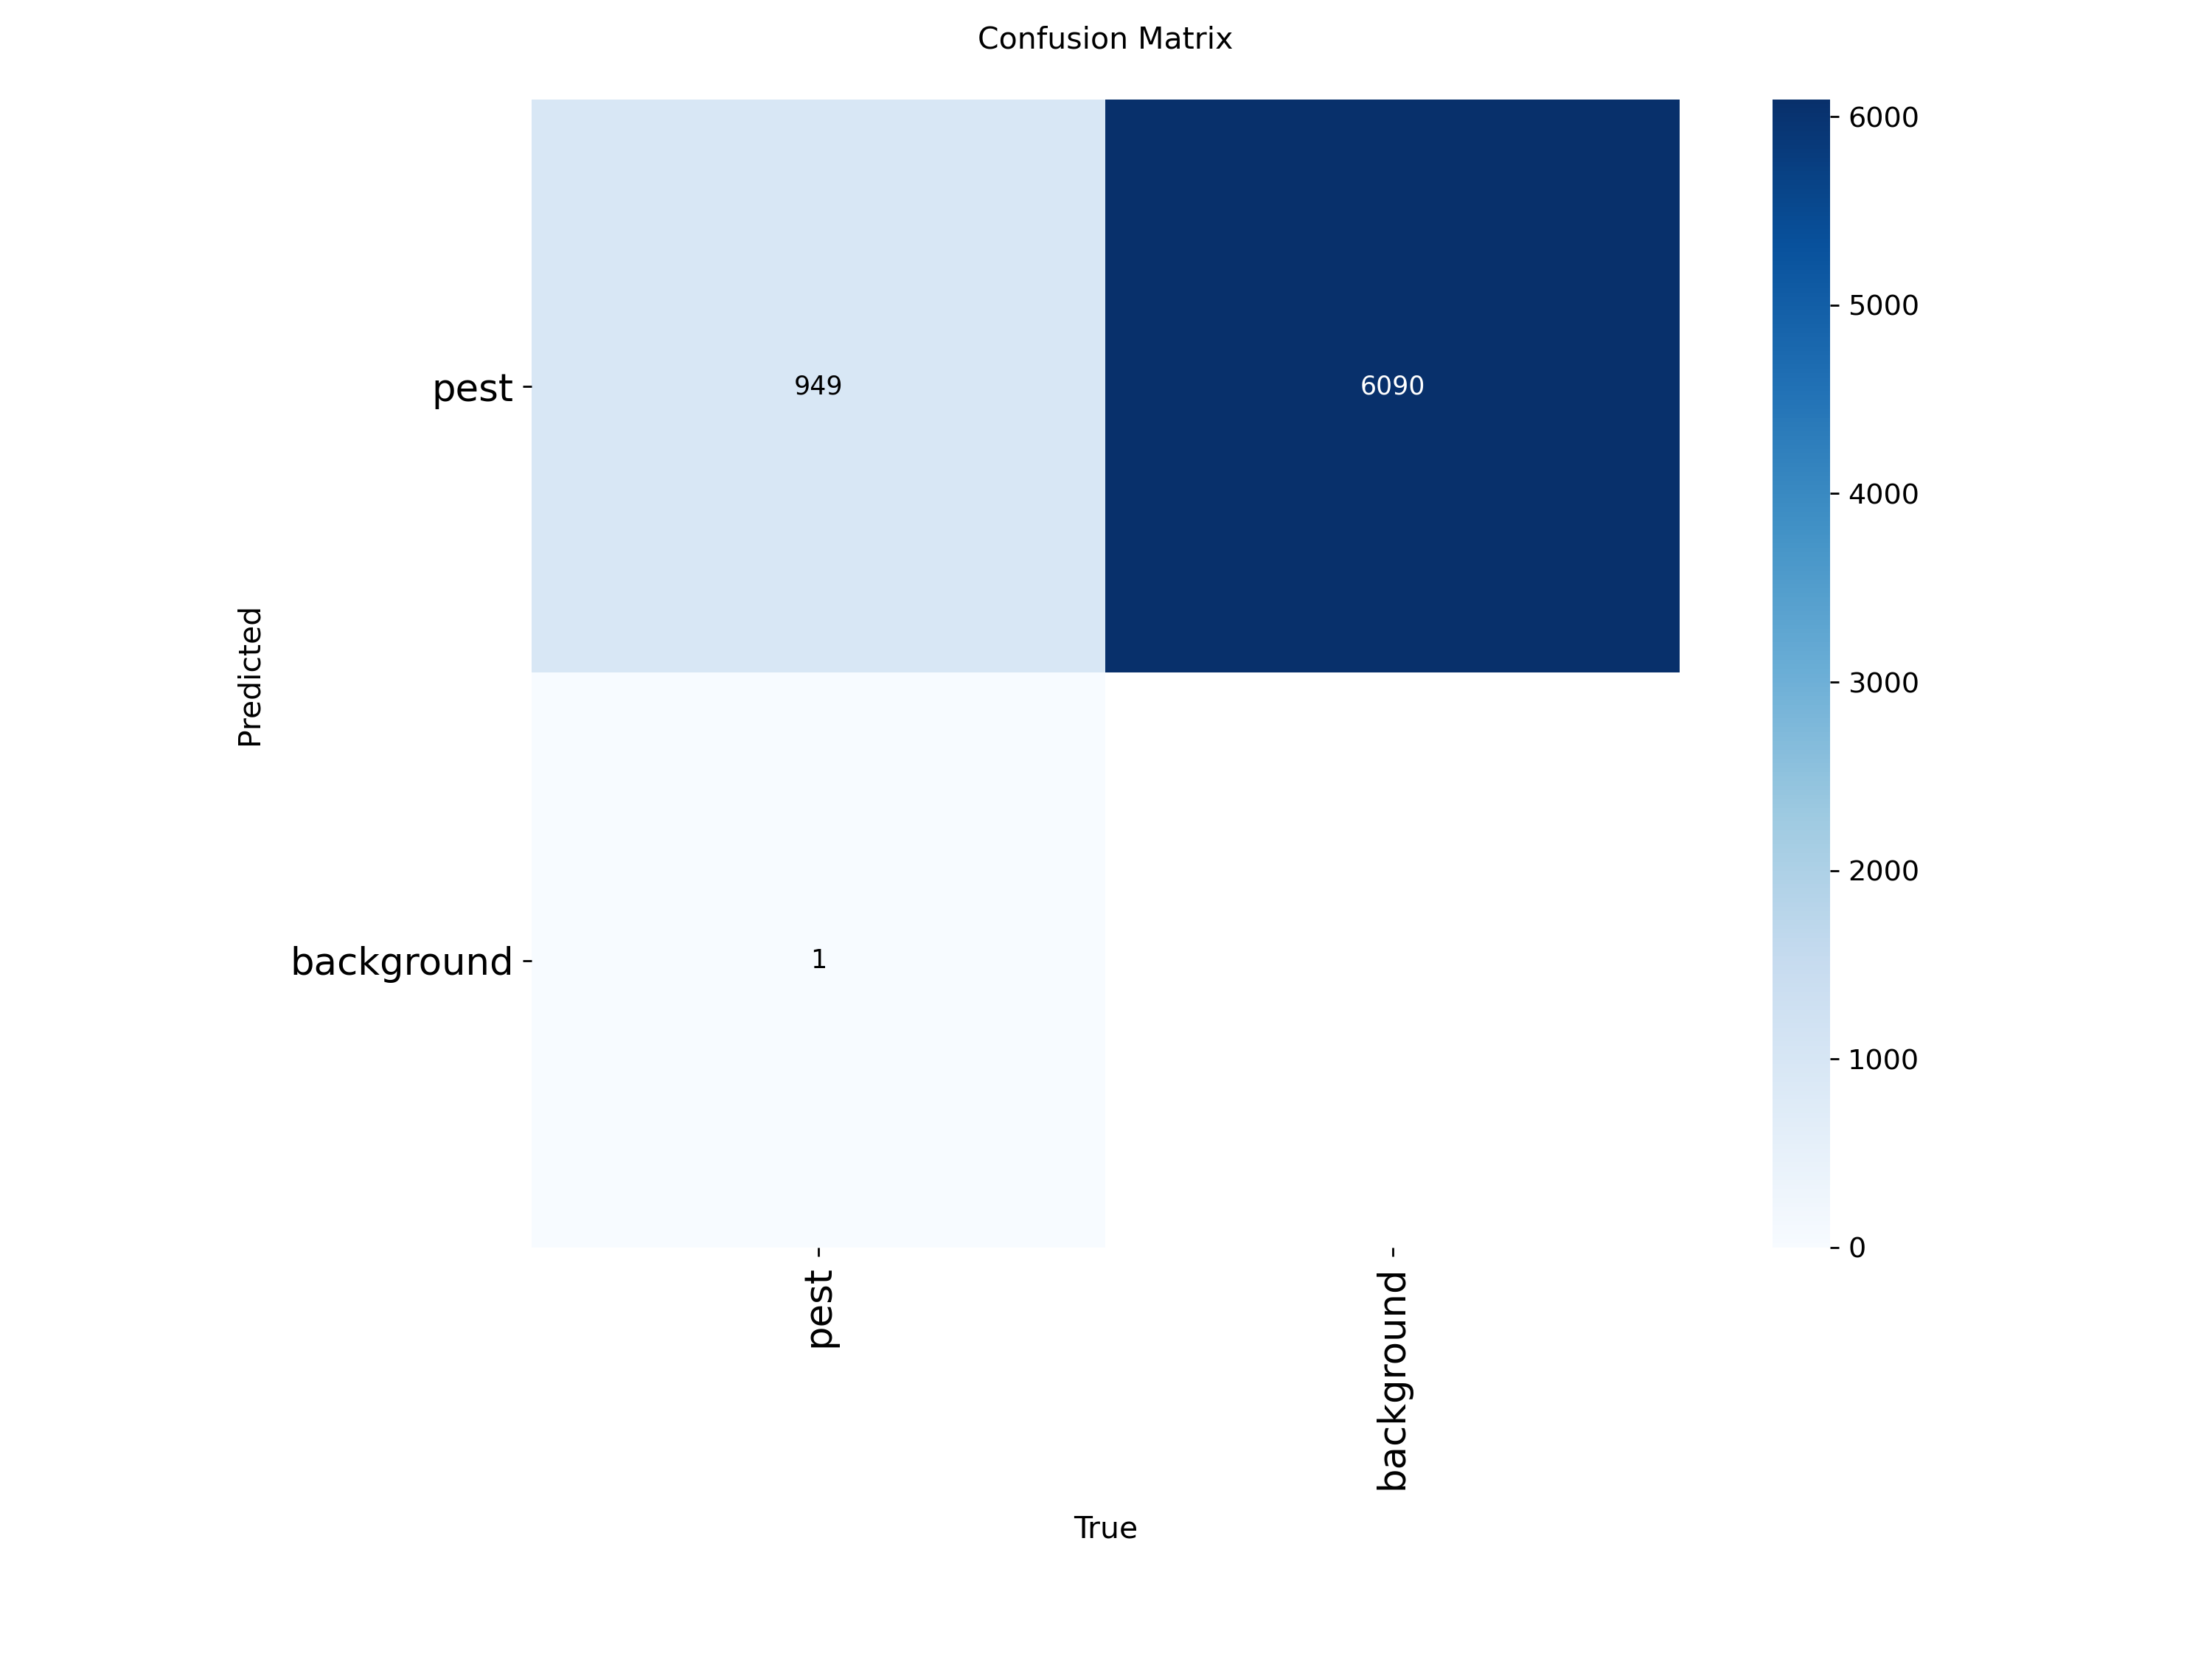

In [15]:
from IPython.display import Image, display
import os

# Đường dẫn chính xác nơi YOLO lưu kết quả train
res_dir = 'runs/detect/train'

print("Biểu đồ tổng hợp Train Loss và mAP:")
display(Image(filename=f'{res_dir}/results.png', width=1000))

print("\nMa trận nhầm lẫn (Confusion Matrix):")
display(Image(filename=f'{res_dir}/confusion_matrix.png', width=800))

In [20]:
!cp /content/runs/detect/train3/weights/best.pt /content/drive/MyDrive/best.pt